# Dimensión dos y descenso de Hadamard

Para $u_{tt}-c^2\Delta u=0$ en $\mathbb R^2$, con $u(x,0)=f(x)$ y $u_t(x,0)=g(x)$, la fórmula de Poisson es

$$
u(x,t)=\frac{\partial}{\partial t}
\left[
\frac{1}{2\pi c}\int_{|y-x|<ct}
\frac{f(y)}{\sqrt{c^2t^2-|y-x|^2}}\,dy
\right]
+\frac{1}{2\pi c}\int_{|y-x|<ct}
\frac{g(y)}{\sqrt{c^2t^2-|y-x|^2}}\,dy.
$$

Se obtiene descendiendo desde la fórmula tridimensional: se consideran datos independientes de una tercera coordenada y se integra sobre la esfera. A diferencia de dimensión tres, en dimensión dos contribuye todo el disco interior. Esto produce una **cola** detrás del frente y el principio fuerte de Huygens falla.

### Proposición 2.10.1 · Promedios esféricos y fórmula de Kirchhoff
Para datos suaves, fija $x\in\mathbb R^3$ y define $M_h(x,r)=(4\pi)^{-1}\int_{\mathbb S^2}h(x+r\omega)\,d\omega$. El teorema de la divergencia da $4\pi r^2\partial_r M_h=\int_{B_r(x)}\Delta h$. Derivando en $r$ se obtiene $\partial_r^2(rM_h)=rM_{\Delta h}$. Entonces $v(r,t)=rM_{u(\cdot,t)}(x,r)$ resuelve la onda 1D con $v(0,t)=0$. Su prolongación impar tiene datos $rM_f,rM_g$. D’Alembert, seguido de $u(x,t)=\partial_r v(0,t)$, da
$$u(x,t)=\partial_t[tM_f(x,ct)]+tM_g(x,ct).$$
Sólo se muestrean los datos en la esfera, incluida su derivada normal en el término de $f$.

### Descenso al disco
Extiende los datos de $\mathbb R^2$ haciéndolos independientes de $x_3$. Sobre cada hemisferio de radio $ct$ se tiene $z=\pm\sqrt{c^2t^2-|y-x|^2}$, con elemento $dS=ct\,dy/\sqrt{c^2t^2-|y-x|^2}$. Sumar ambas hojas en $tM_g$ produce exactamente el factor $1/(2\pi c)$ de la fórmula de Poisson. La singularidad del borde es integrable.

**Prueba observable.** Con $c=1$, $f=0$ y $g(r)=(1-r^2)_+^3$, en el origen la onda 3D es $t g(t)$. En 2D vale $t\int_0^1g(t\sqrt{1-s^2})\,ds$. Después de $t=1$ la primera señal se anula y la segunda sigue siendo positiva.

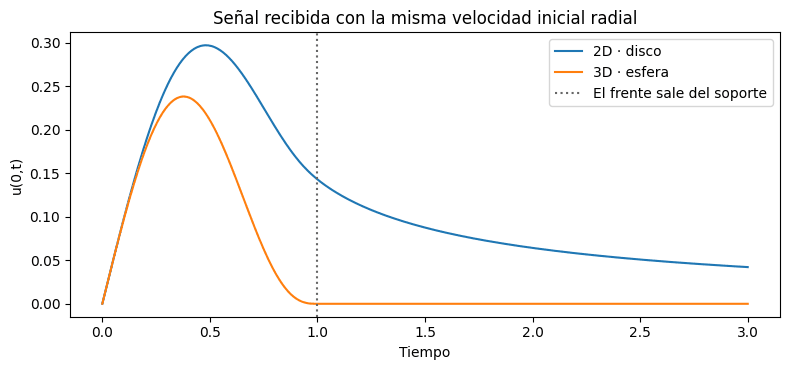

In [2]:
import numpy as np
import matplotlib.pyplot as plt

def velocidad(r):
    return np.maximum(1-r**2, 0)**3

t = np.linspace(0, 3, 450)
nodos, pesos = np.polynomial.legendre.leggauss(96)
s = (nodos+1)/2
radios = t[:, None]*np.sqrt(1-s**2)
onda_2d = t*(velocidad(radios) @ (pesos/2))
onda_3d = t*velocidad(t)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(t, onda_2d, label="2D · disco")
ax.plot(t, onda_3d, label="3D · esfera")
ax.axvline(1, linestyle=":", color="0.4", label="El frente sale del soporte")
ax.set(xlabel="Tiempo", ylabel="u(0,t)", title="Señal recibida con la misma velocidad inicial radial")
ax.legend()
fig.tight_layout()
plt.show()

In [ ]:
from manim import *

class PoissonVsHuygens(Scene):
    def construct(self):
        title = Text("2D: el interior del cono sigue contribuyendo", font_size=34).to_edge(UP)
        center = Dot(color=YELLOW)
        source = Text("dato localizado", font_size=26).next_to(center, DOWN)
        self.play(FadeIn(title), FadeIn(center), FadeIn(source))
        self.wait(4)
        self.play(FadeOut(source))

        rings = VGroup()
        for radius in [0.8, 1.5, 2.2, 2.9]:
            disk = Circle(radius=radius, color=BLUE, fill_color=BLUE, fill_opacity=0.10)
            rings.add(disk)
            self.play(Create(disk), run_time=2)
            self.wait(0.5)
        interior = Text("frente + cola interior", font_size=29).to_edge(DOWN)
        self.play(FadeIn(interior))
        self.wait(3)

from IPython.display import Video, display

with tempconfig({"pixel_width": 2560, "pixel_height": 1440, "frame_rate": 120,
                 "write_to_movie": True, "format": "mp4", "preview": False}):
    escena = PoissonVsHuygens()
    escena.render()
    pelicula = escena.renderer.file_writer.movie_file_path
display(Video(str(pelicula), embed=True))


## Ejercicios esenciales

1. Use descenso de Hadamard para justificar por qué aparece el núcleo $(c^2t^2-r^2)^{-1/2}$ en dos dimensiones. No omita el intervalo permitido de la coordenada adicional.
2. Si $f=0$ y $g$ está soportada en el disco $|x|\le a$, determine una condición suficiente para que $u(x,t)=0$ y explique por qué, después de pasar el frente, puede quedar una cola.

### ★ Variación de nivel General

Compare la propagación de datos suaves y compactamente soportados para la ecuación de onda en $\mathbb R^2$ y $\mathbb R^3$.

a) Escriba las regiones geométricas que intervienen en las fórmulas de representación.  
b) Demuestre velocidad finita de propagación en ambas dimensiones.  
c) Construya un argumento, sin calcular una integral cerrada, que exhiba la falla del principio fuerte de Huygens en dimensión dos.  
d) Indique qué observación física distinguiría experimentalmente ambos comportamientos.